# Working with Classification Trees in Python

## Learning Objectives
Decision Trees are one of the most popular approaches to supervised machine learning. Decison Trees use an inverted tree-like structure to model the relationship between independent variables and a dependent variable. A tree with a categorical dependent variable is known as a **Classification Tree**. By the end of this tutorial, you will have learned:

+ How to import, explore and prepare data
+ How to build a Classification Tree model
+ How to visualize the structure of a Classification Tree
+ How to Prune a Classification Tree

## 1. Collect the Data

In [41]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [42]:
import pandas as pd
import os

# Correct path (MyDrive has no space in Google Colab's actual system path)
folder_path = "/content/drive/MyDrive/Machine Learning/LinkedIn/"

# Load the loan.csv file
loan = pd.read_csv(os.path.join(folder_path, "loan.csv"))
loan.head()

,Income,Loan Amount,Default
0,15,8,No
1,30,8,No
2,5,9,Yes
3,22,10,No
4,33,12,No


The data is already clean - so I don't need to tidy it up

## 2. Explore the Data

In [43]:
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Income       30 non-null     int64 
 1   Loan Amount  30 non-null     int64 
 2   Default      30 non-null     object
dtypes: int64(2), object(1)
memory usage: 852.0+ bytes


This is a small dataset with only 30 rows - but its good for practice

In [44]:
loan.describe()

,Income,Loan Amount
count,30.000000,30.000000
mean,18.766667,51.966667
std,8.572946,34.055212
min,5.000000,8.000000
25%,13.000000,21.250000
50%,18.000000,49.000000
75%,25.500000,79.500000
max,34.000000,110.000000


In [45]:
%matplotlib inline
from matplotlib import pyplot as plt
import seaborn as sns

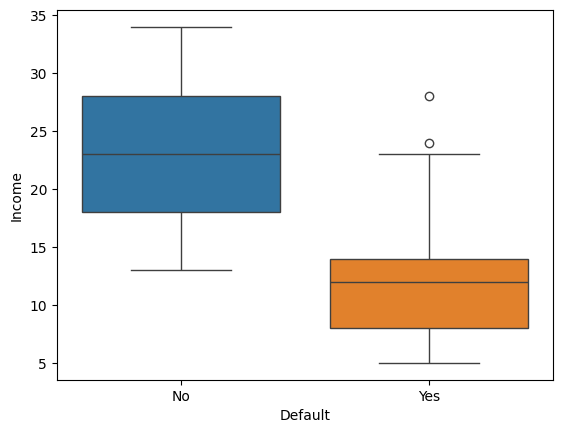

In [46]:
ax = sns.boxplot(data = loan, x = 'Default', y = 'Income', hue='Default')

**Income by default status**

Income separates the two groups clearly. People who didn't default had a median income of about 23, with the middle half between roughly 18 and 28. People who did default had a median of about 12, with the middle half between 8 and 14. The two boxes don't overlap at all, so most defaulters earn less than most non-defaulters. The ranges do overlap at the edges: the lowest non-defaulter is at about 13, the highest defaulter whisker reaches about 23, and two defaulters stand out as outliers at about 24 and 28. Income looks like the stronger predictor of the two, which fits with the tree using it for its first split.

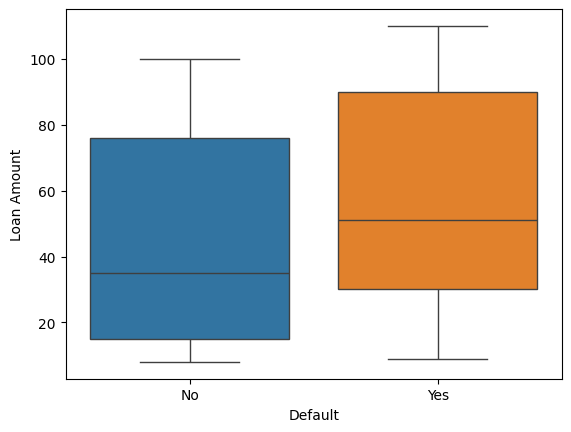

In [47]:
ax = sns.boxplot(data = loan, x = 'Default', y = 'Loan Amount', hue='Default')

**Loan amount by default status**

Loan amount is a much weaker signal. Defaulters tended to borrow a bit more (median about 51, compared with about 35 for non-defaulters), but both groups are very spread out. The middle half runs from about 15 to 76 for non-defaulters and from about 30 to 90 for defaulters, so the boxes overlap heavily, and both groups cover almost the full range from about 10 to 100+. On its own, loan amount wouldn't tell you much about whether someone will default. Any value it adds is likely to come from combining it with income.

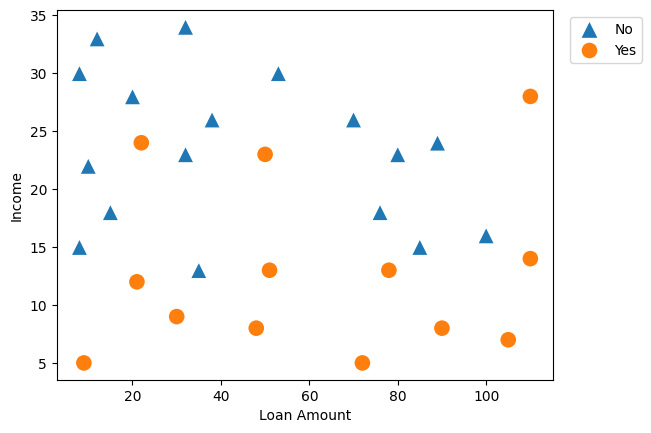

In [48]:
ax = sns.scatterplot(data = loan,
                     x = 'Loan Amount',
                     y = 'Income',
                     hue = 'Default',
                     style = 'Default',
                     markers = ['^','o'],
                     s = 150)
ax = plt.legend(bbox_to_anchor = (1.02, 1), loc = 'upper left')

The scatter plot shows that the two classes are mostly separated by income: most defaulters earn under about 15, and most non-defaulters earn more. They aren't perfectly separable, though. There's some overlap around incomes of 13–16, and a few higher-income borrowers still defaulted. Loan amount doesn't add much, since both classes are spread across its full range. That suggests a simple income threshold would get most predictions right, and a tree that tries to capture every exception is likely to overfit.

## 3. Prepare the Data

In [49]:
y = loan['Default']

In [50]:
X = loan.drop(columns = 'Default')

In [51]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    train_size = 0.8,
                                                    stratify = y,
                                                    random_state = 1234)

In [52]:
X_train.shape, X_test.shape

((24, 2), (6, 2))

## 4. Train and Evaluate the Classification Tree

In [53]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(random_state = 1234)

In [54]:
model = classifier.fit(X_train, y_train)

## 5. Visualize the Classification Tree

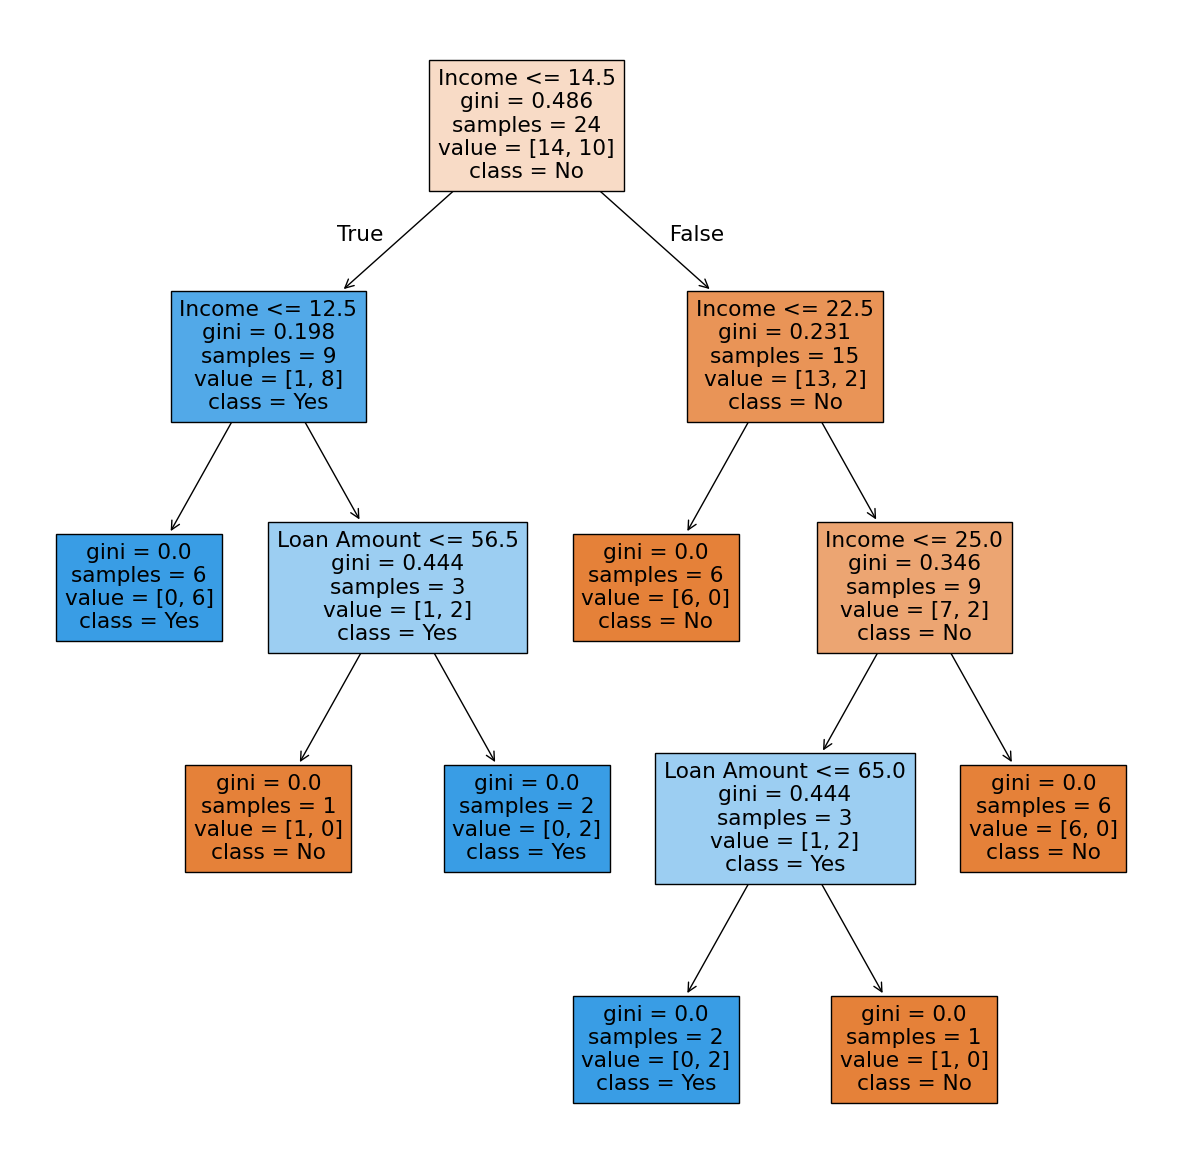

In [55]:
from sklearn import tree
plt.figure(figsize = (15,15))
tree.plot_tree(
    model,
    feature_names = list(X.columns),
    class_names = ['No','Yes'],
    filled = True
);

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


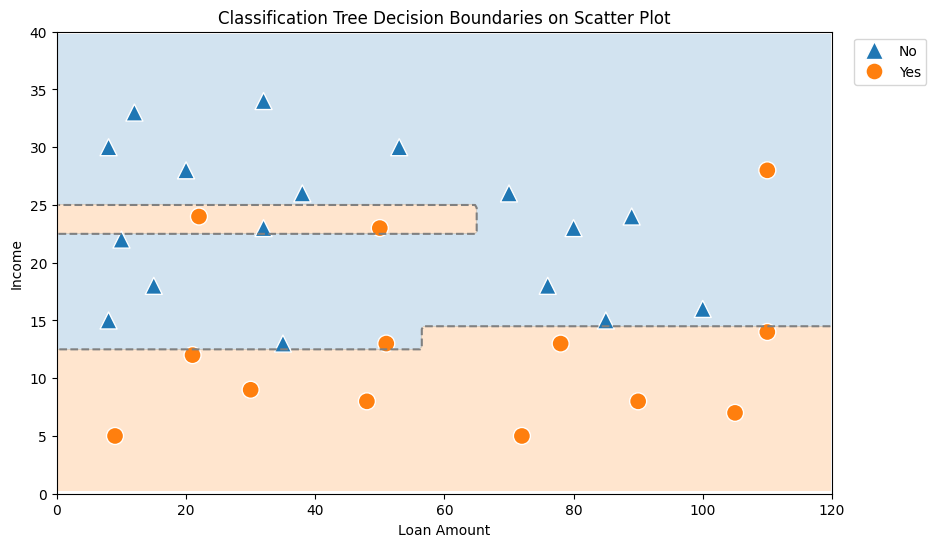

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

plt.figure(figsize=(10, 6))

# 1. Grid, offset by half a step so contour lines land exactly on split thresholds
x_min, x_max = 0, 120
y_min, y_max = 0, 40
step = 0.5
xx, yy = np.meshgrid(np.arange(x_min + step/2, x_max, step),
                     np.arange(y_min + step/2, y_max, step))

# Predict on the grid (feature order: Income, Loan Amount)
y_pred_grid = model.predict(np.c_[yy.ravel(), xx.ravel()])
le = LabelEncoder()
le.fit(['No', 'Yes'])
Z = le.transform(y_pred_grid).reshape(xx.shape)

# Match region colours to seaborn's default point colours (No = blue, Yes = orange)
palette = sns.color_palette()
region_colors = [palette[0], palette[1]]

# 2. Filled regions: one band per class
plt.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=region_colors, alpha=0.2)

# 3. Boundary line only where the class changes
plt.contour(xx, yy, Z, levels=[0.5], colors='gray', linestyles='--', linewidths=1.5)

# 4. Scatter on top
ax = sns.scatterplot(data=loan,
                     x='Loan Amount',
                     y='Income',
                     hue='Default',
                     style='Default',
                     markers=['^', 'o'],
                     s=150)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xlabel('Loan Amount')
plt.ylabel('Income')
plt.title('Classification Tree Decision Boundaries on Scatter Plot')
plt.show()

<table>
  <thead>
    <tr>
      <th>Tree split</th>
      <th>What it predicts</th>
      <th>In the plot</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Income &le; 12.5</td>
      <td>Yes (any loan)</td>
      <td>Bottom line at ~12.5, left side &#10003;</td>
    </tr>
    <tr>
      <td>12.5 &lt; Income &le; 14.5, Loan &le; 56.5</td>
      <td>No</td>
      <td>Gap between 12.5 and 14.5 on the left &#10003;</td>
    </tr>
    <tr>
      <td>12.5 &lt; Income &le; 14.5, Loan &gt; 56.5</td>
      <td>Yes</td>
      <td>Step up at x &asymp; 56.5 to 14.5 &#10003;</td>
    </tr>
    <tr>
      <td>14.5 &lt; Income &le; 22.5</td>
      <td>No</td>
      <td>No line needed, since it's No on both sides &#10003;</td>
    </tr>
    <tr>
      <td>22.5 &lt; Income &le; 25, Loan &le; 65</td>
      <td>Yes</td>
      <td>Thin box from 0–65 between 22.5 and 25 &#10003;</td>
    </tr>
    <tr>
      <td>22.5 &lt; Income &le; 25, Loan &gt; 65</td>
      <td>No</td>
      <td>Box closes at x &asymp; 65 &#10003;</td>
    </tr>
    <tr>
      <td>Income &gt; 25</td>
      <td>No</td>
      <td>No line &#10003;</td>
    </tr>
  </tbody>
</table>

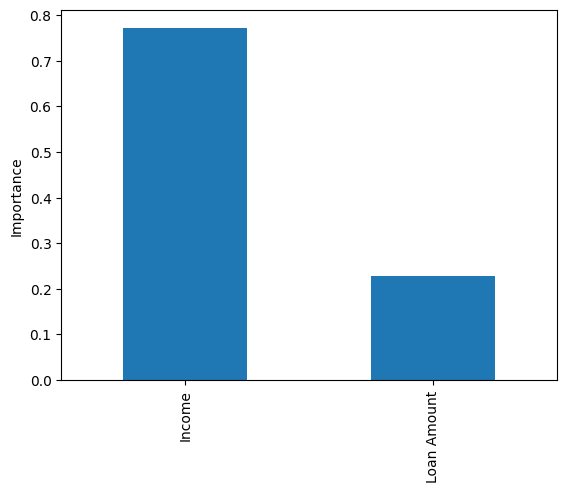

In [57]:
importance = model.feature_importances_
feature_importance = pd.Series(importance, index = X.columns)
feature_importance.plot(kind = 'bar')
plt.ylabel('Importance');

## 6. Prune the Classification Tree

In [58]:
model.score(X_train, y_train)

1.0

In [59]:
model.score(X_test, y_test)

0.5

The resulting score (0.5) means the unpruned model only correctly classified 50% of the test samples because it overfitted the training set

In [60]:
grid = {}

In [61]:
from sklearn.model_selection import GridSearchCV
classifier = DecisionTreeClassifier(random_state = 1234)
# Pass hyperparameters to search through via the param_grid parameter
param_grid = {'max_depth': [3, 4, 5, 6]}
gcv = GridSearchCV(classifier, param_grid)
gcv.fit(X_train, y_train)

GridSearchCV(estimator=DecisionTreeClassifier(random_state=1234),
             param_grid={'max_depth': [3, 4, 5, 6]})

This cell uses grid search to pre-prune the tree by limiting `max_depth`. It tries depths 3–6, scores each with 5-fold cross-validation on the training data, and keeps the depth with the best average score.

**Why grid search chose depth 3**

Grid search tested all four depths (3, 4, 5 and 6). For each one, it trained and scored a tree on different parts of the training data and took the average score. It then kept the depth with the best average.

Depth 3 came out on top. It may have scored highest, or several depths may have tied. My tree never grows deeper than 4, so depths 4, 5 and 6 probably produce the same tree with the same score. When scores tie, grid search picks the first value in the list, which is 3.

In [62]:
model_ = gcv.best_estimator_
model_

DecisionTreeClassifier(max_depth=3, random_state=1234)

This cell retrieves the best tree found by the grid search and shows its settings.

In [63]:
model_.score(X_train, y_train)

0.9583333333333334

In [64]:
model_.score(X_test, y_test)

0.3333333333333333

**Why test accuracy dropped from 50% to 33.3%**

Limiting the tree to depth 3 removed one split, the one that checked Loan Amount for people with an income between 22.5 and 25. Without it, the tree predicts "Yes" for everyone in that income range.

One test borrower in that range didn't default, so the tree now gets them wrong. That's one extra mistake out of 6, which takes accuracy from 3/6 (50%) to 2/6 (33.3%).

The real problem was the tiny 22.5–25 income band itself, and limiting depth didn't remove it.

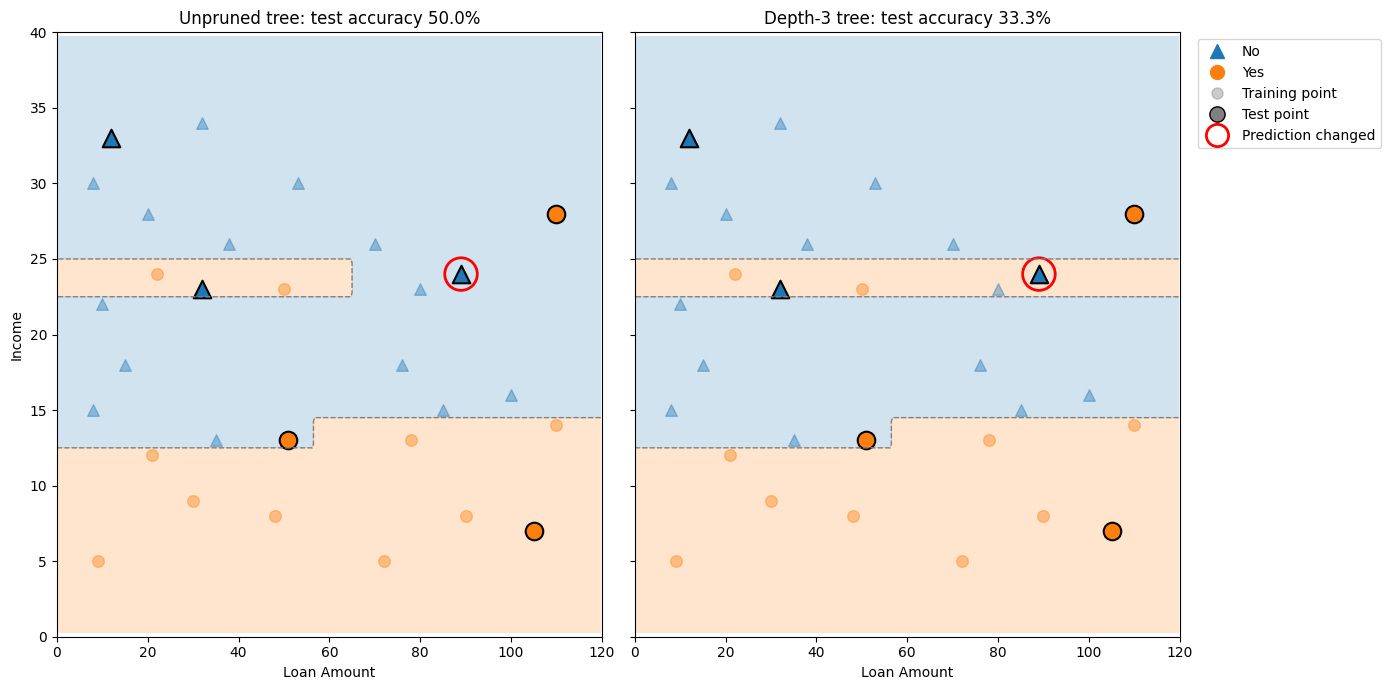

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.tree import DecisionTreeClassifier

# Rebuild the depth-3 tree (model_ was overwritten by the second grid search)
depth3 = DecisionTreeClassifier(max_depth=3, random_state=1234).fit(X_train, y_train)

# Grid of points covering the plot (feature order: Income, Loan Amount)
xx, yy = np.meshgrid(np.arange(0.25, 120, 0.5), np.arange(0.25, 40, 0.5))
grid_df = pd.DataFrame(np.c_[yy.ravel(), xx.ravel()], columns=X.columns)

palette = sns.color_palette()
colours = {'No': palette[0], 'Yes': palette[1]}
markers = {'No': '^', 'Yes': 'o'}

# Test points whose prediction differs between the two trees
changed = model.predict(X_test) != depth3.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

for ax, m, name in zip(axes, [model, depth3], ['Unpruned tree', 'Depth-3 tree']):
    # Shaded prediction regions
    Z = (m.predict(grid_df) == 'Yes').astype(int).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
                colors=[colours['No'], colours['Yes']], alpha=0.2)
    ax.contour(xx, yy, Z, levels=[0.5], colors='gray', linestyles='--', linewidths=1)

    for label in ['No', 'Yes']:
        # Training points: small and faded
        tr = y_train == label
        ax.scatter(X_train.loc[tr, 'Loan Amount'], X_train.loc[tr, 'Income'],
                   color=colours[label], marker=markers[label], s=70, alpha=0.4)
        # Test points: large with a black outline
        te = y_test == label
        ax.scatter(X_test.loc[te, 'Loan Amount'], X_test.loc[te, 'Income'],
                   color=colours[label], marker=markers[label], s=160,
                   edgecolor='black', linewidth=1.5)

    # Red ring around the test point whose prediction changed
    ax.scatter(X_test.loc[changed, 'Loan Amount'], X_test.loc[changed, 'Income'],
               s=550, facecolors='none', edgecolors='red', linewidths=2)

    ax.set_title(f'{name}: test accuracy {m.score(X_test, y_test):.1%}')
    ax.set_xlabel('Loan Amount')
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 40)

axes[0].set_ylabel('Income')

legend = [
    Line2D([], [], marker='^', ls='', color=colours['No'], ms=10, label='No'),
    Line2D([], [], marker='o', ls='', color=colours['Yes'], ms=10, label='Yes'),
    Line2D([], [], marker='o', ls='', color='grey', alpha=0.4, ms=8, label='Training point'),
    Line2D([], [], marker='o', ls='', color='grey', mec='black', ms=11, label='Test point'),
    Line2D([], [], marker='o', ls='', mfc='none', mec='red', mew=2, ms=16, label='Prediction changed'),
]
axes[1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### What are Hyperparameters and Why Use Grid Search?

### Hyperparameters and grid search

Some settings in a model are learned from the data, like where a decision tree places its splits. Others, called hyperparameters, have to be chosen before training. For a decision tree, the three I tuned are:

- `max_depth`: how many levels the tree can grow
- `min_samples_split`: the minimum number of rows a node needs before it can be split
- `min_samples_leaf`: the minimum number of rows allowed in a final leaf

All three limit how complex the tree can get. If they're too loose, the tree overfits and memorises quirks of the training data. If they're too tight, it underfits and misses real patterns.

Rather than trying values by hand, I used `GridSearchCV`. It trains a tree for every combination in the grid and scores each one with 5-fold cross-validation on the training data. The combination with the best average score is kept. This only searches the values I gave it, and the score is an estimate, so it doesn't guarantee the best possible model.

In [65]:
'''
 A "grid" (dictionary) of settings—such as max_depth, min_samples_split,
 and min_samples_leaf. GridSearchCV automatically trains and evaluates a model
 for every single possible combination of those values.
'''

hyperparameters = {'max_depth': [2, 3, 4, 5, 6],
                   'min_samples_split': [2, 3, 4],
                   'min_samples_leaf': [1, 2, 3, 4, 5, 6]}

In [66]:
from sklearn.model_selection import GridSearchCV
classifier = DecisionTreeClassifier(random_state = 1234)
gcv = GridSearchCV(classifier, hyperparameters)
gcv.fit(X_train, y_train)

GridSearchCV(estimator=DecisionTreeClassifier(random_state=1234),
             param_grid={'max_depth': [2, 3, 4, 5, 6],
                         'min_samples_leaf': [1, 2, 3, 4, 5, 6],
                         'min_samples_split': [2, 3, 4]})

In [76]:
model_ = gcv.best_estimator_

**Why the second grid search chose a different tree**

This cell gets the best tree from the second grid search (cell 66). That search was much bigger. As well as depth, it also tried different values for `min_samples_split` and `min_samples_leaf`, which gives 90 combinations instead of 4.

The winner was `max_depth=2` and `min_samples_leaf=6`. Requiring at least 6 loans in every leaf stops the tree from creating small splits based on just 1–3 points, which were the splits that caused overfitting in the earlier trees.

The scores in the next two cells show the effect. Training accuracy is 87.5% (21 of 24) and test accuracy is 83.3% (5 of 6). The earlier trees scored much higher on training data than on test data. For this tree the two scores are close, so it's learned a general pattern rather than memorising the training points. With only 6 test loans, though, each mistake moves the test score by about 17 percentage points.

In [77]:
model_.score(X_train, y_train)

0.875

In [78]:
model_.score(X_test, y_test)

0.8333333333333334

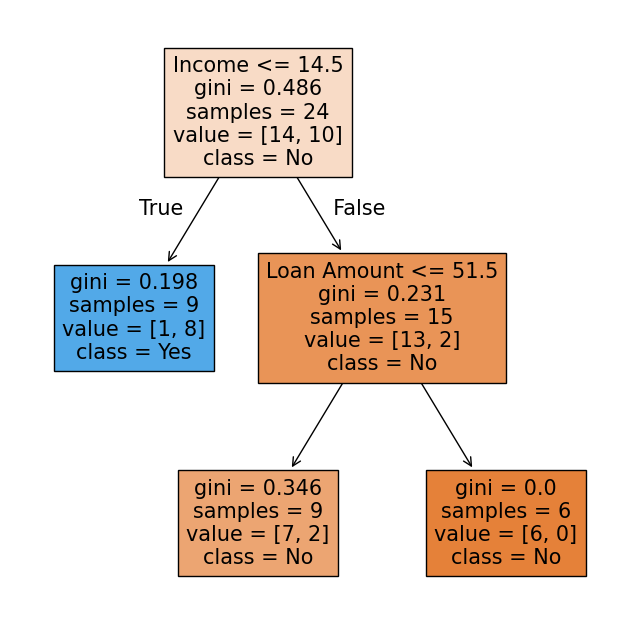

In [70]:
plt.figure(figsize = (8,8))
tree.plot_tree(model_,
                   feature_names = list(X.columns),
                   class_names = ['No','Yes'],
                   filled = True);

In [71]:
pd.DataFrame({'Unpruned': model.feature_importances_,
              'Pruned': model_.feature_importances_},
             index=X.columns).round(2)

,Unpruned,Pruned
Income,0.77,0.95
Loan Amount,0.23,0.05


Both the unpruned and pruned trees make the same first split, on Income at 14.5. Pruning removed the small extra splits, including the two Loan Amount splits that were each based on only 3 samples, so Loan Amount’s score dropped.

# **SUMMARY**

My unpruned tree fitted the training data perfectly (100%) but scored only 50% on the test set, so it was clearly overfitting. It had learned splits that matched individual training points rather than a general pattern.

I first tried limiting max_depth (3 to 6) with GridSearchCV. It chose a depth of 3, which gave 95.8% on training and 33.3% on test. On the face of it, that’s worse, but the test set has only 6 loans, so the drop from 50% to 33.3% is just one extra misclassification.

I then widened the search to include min_samples_split (2 to 4) and min_samples_leaf (1 to 6). The best tree was much simpler: max_depth=2 and min_samples_leaf=6, with min_samples_split left at the default of 2. Training accuracy fell to 87.5% (21/24), and test accuracy rose to 83.3% (5/6).

The pruned tree is a better model because it gives up some training accuracy for simpler rules that hold up better on new data. With only 6 test rows, though, each prediction is worth about 17 percentage points, so the cross-validation score is a fairer measure than the test score alone.